## Import

In [1]:
import torch
from torch import nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm

from sklearn.model_selection import train_test_split

from torch.optim import AdamW
from transformers.optimization import get_cosine_schedule_with_warmup
from transformers import BertModel
from torch.utils.data import DataLoader

from kobert_tokenizer import KoBERTTokenizer

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Dataset to use

In [ ]:
data = pd.read_csv('../data/ai_hub_undersampled.csv')

### 중복값 및 결측치 삭제

In [4]:
data = data.drop_duplicates()

In [5]:
data = data.dropna()

### 텍스트, 라벨로 묶기

In [6]:
data_list = []
for review, label in zip (data['RawText'], data['GeneralPolarity']):
    data_zip = []
    data_zip.append(review)
    data_zip.append(label)

    data_list.append(data_zip)

### 라벨 분포 확인

In [7]:
import seaborn as sns

<Axes: xlabel='GeneralPolarity', ylabel='count'>

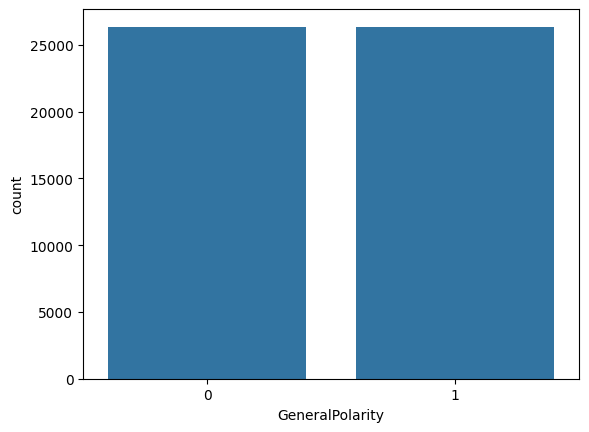

In [8]:
sns.countplot(x="GeneralPolarity", data=data)

### 분포 유지하면서 데이터 분할

In [9]:
from sklearn.model_selection import train_test_split

# 데이터와 라벨 분리
X = [data[0] for data in data_list]  # 리뷰 텍스트
y = [data[1] for data in data_list]  # 라벨 (-1, 1)

In [10]:
# stratify 매개변수에 라벨(y)을 전달하여 분포 유지
dataset_train, dataset_test = train_test_split(data_list, test_size=0.2, shuffle=True, stratify=y, random_state=32)

### 원본 라벨 분포와 비교

In [11]:
import numpy as np

# 원본 데이터셋의 라벨 분포 확인
original_labels = np.array([data[1] for data in data_list])
unique, counts = np.unique(original_labels, return_counts=True)
original_distribution = dict(zip(unique, counts / len(original_labels)))

# 학습용 데이터셋의 라벨 분포 확인
train_labels = np.array([data[1] for data in dataset_train])
unique, counts = np.unique(train_labels, return_counts=True)
train_distribution = dict(zip(unique, counts / len(train_labels)))

# 테스트용 데이터셋의 라벨 분포 확인
test_labels = np.array([data[1] for data in dataset_test])
unique, counts = np.unique(test_labels, return_counts=True)
test_distribution = dict(zip(unique, counts / len(test_labels)))

print("원본 데이터셋 라벨 분포:", original_distribution)
print("학습용 데이터셋 라벨 분포:", train_distribution)
print("테스트용 데이터셋 라벨 분포:", test_distribution)


원본 데이터셋 라벨 분포: {0: 0.5, 1: 0.5}
학습용 데이터셋 라벨 분포: {0: 0.5000118519923199, 1: 0.4999881480076801}
테스트용 데이터셋 라벨 분포: {0: 0.4999525931544515, 1: 0.5000474068455485}


### train, valid 분할

In [12]:
# 데이터와 라벨 분리
X_train = [data[0] for data in dataset_train]  # 리뷰 텍스트
y_train = [data[1] for data in dataset_train]  # 라벨 (-1, 1)

In [13]:
train, valid = train_test_split(dataset_train, test_size=0.2, shuffle=True, stratify=y_train, random_state=32)

<hr>

## Tokenization

In [14]:
bertmodel = BertModel.from_pretrained("skt/kobert-base-v1")
tokenizer = KoBERTTokenizer.from_pretrained("skt/kobert-base-v1")

The tokenizer class you load from this checkpoint is not the same type as the class this function is called from. It may result in unexpected tokenization. 
The tokenizer class you load from this checkpoint is 'XLNetTokenizer'. 
The class this function is called from is 'KoBERTTokenizer'.


## BERTDataset

학습에 이용될 DataLoader에 넣을 Dataset을 정의

In [15]:
class BERTDataset(Dataset):
    def __init__(self, data, sent_idx, label_idx, tokenizer, max_len):
        self.data = data
        self.sent_idx = sent_idx
        self.label_idx = label_idx
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __getitem__(self, idx):
        text = self.data[idx][self.sent_idx]
        label = self.data[idx][self.label_idx]

        encoding = self.tokenizer(
            text,
            padding='max_length',
            truncation=True,
            max_length=self.max_len,
            return_tensors='pt'
        )

        # tensor 차원에서 batch 차원 제거
        input_ids = encoding['input_ids'].squeeze(0)
        attention_mask = encoding['attention_mask'].squeeze(0)
        token_type_ids = encoding['token_type_ids'].squeeze(0)

        return input_ids, attention_mask, token_type_ids, torch.tensor(label)

    def __len__(self):
        return len(self.data)

## DataLoader

In [16]:
max_len = 64
batch_size = 16

train_dataset = BERTDataset(train, 0, 1, tokenizer, max_len)
valid_dataset = BERTDataset(valid, 0, 1, tokenizer, max_len)

train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valid_dataloader = DataLoader(valid_dataset, batch_size=batch_size)

## KoBERT Model 구현

In [17]:
class BERTClassifier(nn.Module):
    def __init__(self, bert, hidden_size=768, num_classes=2, dr_rate=0.5):
        super(BERTClassifier, self).__init__()
        self.bert = bert
        self.dropout = nn.Dropout(p=dr_rate)
        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, input_ids, attention_mask, token_type_ids):
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )
        pooled_output = outputs.pooler_output
        out = self.dropout(pooled_output)
        return self.classifier(out)

In [18]:
model = BERTClassifier(bertmodel)
model.to(device)

BERTClassifier(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(8002, 768, padding_idx=1)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise

## Optimizer, Schedule

In [19]:
no_decay = ['bias', 'LayerNorm.weight']

optimizer_grouped_parameters = [
    {
        'params': [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
        'weight_decay': 0.01
    },
    {
        'params': [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
        'weight_decay': 0.0
    }
]

learning_rate = 5e-5
optimizer = AdamW(optimizer_grouped_parameters, lr=learning_rate)

num_epochs = 5
t_total = len(train_dataloader) * num_epochs
warmup_ratio = 0.1
warmup_step = int(t_total * warmup_ratio)

scheduler = get_cosine_schedule_with_warmup(optimizer, num_warmup_steps=warmup_step, num_training_steps=t_total)

loss_fn = nn.CrossEntropyLoss()

In [20]:
def calc_accuracy(logits, labels):
    preds = torch.argmax(logits, dim=1)
    correct = (preds == labels).sum().item()
    return correct / len(labels)

from sklearn.metrics import f1_score

def calc_f1_score(logits, labels):
    preds = torch.argmax(logits, dim=1).cpu().numpy()
    labels = labels.cpu().numpy()
    return f1_score(labels, preds, average='weighted')

## Train

In [ ]:
max_grad_norm = 1.0
log_interval = 10

train_acc_history, train_f1_history = [], []
valid_acc_history, valid_f1_history = [], []

for epoch in range(num_epochs):
    model.train()
    train_acc = 0
    train_f1 = 0
    for batch_idx, batch in enumerate(tqdm(train_dataloader)):
        input_ids, attention_mask, token_type_ids, labels = [x.to(device) for x in batch]

        optimizer.zero_grad()
        outputs = model(input_ids, attention_mask, token_type_ids)
        loss = loss_fn(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
        optimizer.step()
        scheduler.step()

        train_acc += calc_accuracy(outputs, labels)
        train_f1 += calc_f1_score(outputs, labels)

        if (batch_idx + 1) % log_interval == 0:
            print(f"Epoch {epoch+1} Batch {batch_idx+1} Loss {loss.item():.4f} Train Acc {train_acc/(batch_idx+1):.4f} Train F1 {train_f1/(batch_idx+1):.4f}")

    train_acc /= len(train_dataloader)
    train_f1 /= len(train_dataloader)
    train_acc_history.append(train_acc)
    train_f1_history.append(train_f1)
    print(f"Epoch {epoch+1} Train Acc: {train_acc:.4f}, Train F1: {train_f1:.4f}")

    model.eval()
    valid_acc = 0
    valid_f1 = 0
    with torch.no_grad():
        for batch in tqdm(valid_dataloader):
            input_ids, attention_mask, token_type_ids, labels = [x.to(device) for x in batch]
            outputs = model(input_ids, attention_mask, token_type_ids)
            valid_acc += calc_accuracy(outputs, labels)
            valid_f1 += calc_f1_score(outputs, labels)

    valid_acc /= len(valid_dataloader)
    valid_f1 /= len(valid_dataloader)
    valid_acc_history.append(valid_acc)
    valid_f1_history.append(valid_f1)
    print(f"Epoch {epoch+1} Valid Acc: {valid_acc:.4f}, Valid F1: {valid_f1:.4f}")


## 학습 시각화

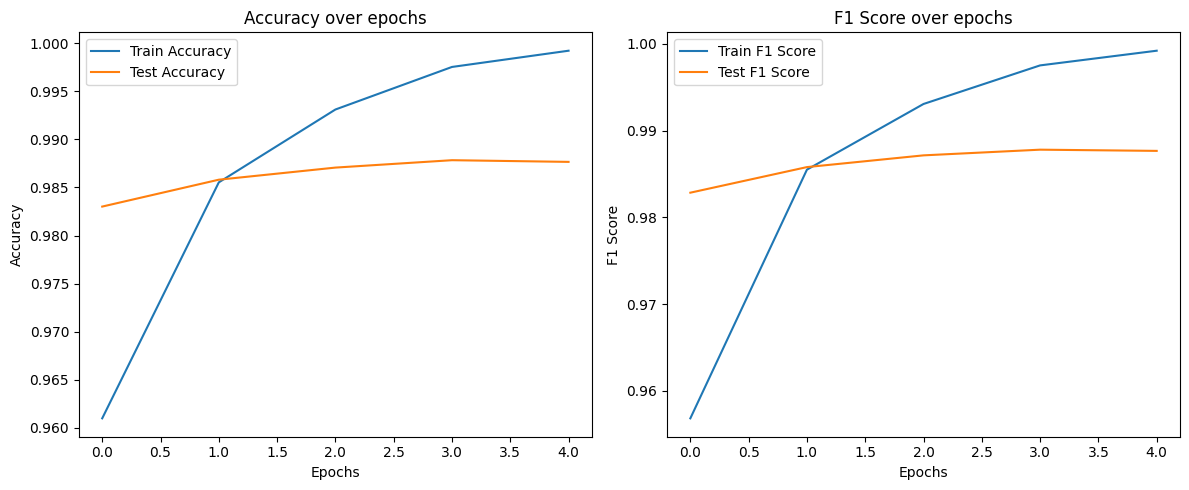

In [60]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(12,5))

# 정확도 시각화
plt.subplot(1, 2, 1)
plt.plot(epochs, train_acc_history, label='Train Accuracy')
plt.plot(epochs, valid_acc_history, label='Valid Accuracy')
plt.title('Accuracy over epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# F1 점수 시각화
plt.subplot(1, 2, 2)
plt.plot(epochs, train_f1_history, label='Train F1')
plt.plot(epochs, valid_f1_history, label='Valid F1')
plt.title('F1 Score over epochs')
plt.xlabel('Epoch')
plt.ylabel('F1 Score')
plt.legend()

plt.show()

## Model Save

In [ ]:
import os

# 현재 디렉토리: .../01_kobert_finetuning_prediction/code
current_dir = os.getcwd()

# 'code'의 상위 디렉토리
parent_dir = os.path.dirname(current_dir)

# 그 아래 'model' 폴더
save_dir = os.path.join(parent_dir, 'model')

# 혹시 없으면 생성
os.makedirs(save_dir, exist_ok=True)

# 저장 경로
save_path = os.path.join(save_dir, 'kobert_under.pt')

torch.save(model.state_dict(), save_path)
print(f"Model saved to {save_path}")
